# Predicting a variant

This tutorial demonstrates how to use `predict_variant` to predict variant
effects across bulk RNA-seq and pseudobulk scRNA-seq tracks. We predict the
effect of chr2:219243701:C>T on *GLB1L* expression in CD14-positive monocytes
in blood (`UBERON:0000178_CL:0001054`) by comparing reference (REF) and
alternate (ALT) allele predictions.

Key activities:

*   Choose a condition and output type, and define a `genome.Variant` and `genome.Interval`
*   Make variant effect predictions using `predict_variant`
*   Visualize reference versus alternate (REF/ALT) predictions

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [2]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)).

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

We first load GENCODE gene and transcript annotations in GTF format (see
[GENCODE data format](https://www.gencodegenes.org/pages/data_format.html)):

In [4]:
# The GTF file contains information on the location of all transcripts.
# Note that we use genome assembly hg38 for human.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Get the MANE transcripts (one curated transcript per locus).
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts_mane = gene_annotation.filter_to_mane_select_transcript(
    gtf_transcripts
)

# Set up transcript extractors using the information in the GTF file.
transcript_extractor_mane = transcript_utils.TranscriptExtractor(
    gtf_transcripts_mane
)

## Predict variant (bulk)

`predict_variant` predicts tracks for the reference (REF) and alternate (ALT)
allele sequences. It takes a condition, a `genome.Variant`, a `genome.Interval`
that contains the variant, and a list of requested output types.

### Set condition and output type

Use a reference condition CURIE from
[Choosing a condition](https://www.alphagenomedocs.com/colabs/v2/choosing_a_condition.html).

In [5]:
# Set condition.
target_condition = 'UBERON:0000178_CL:0001054'  # CD14-positive monocytes in blood.

# Set output types.
target_output = [
    dna_client.OutputType.RNA_SEQ,  # Gene expression.
]

> **Tip:** For expression conditioning (`cell_conditioning=`) alongside `cell_condition_name=` with your own human scRNA-seq counts, request `dna_client.OutputType.SC_GENE_EXPRESSION_DENOISED` for denoised single-cell gene expression; see [Conditioning on your own single-cell data](https://www.alphagenomedocs.com/colabs/v2/conditioning_on_single_cell_data.html).

### Define variant and interval

Define a variant by creating a `genome.Variant` object (see
[Selecting a genomic region](https://www.alphagenomedocs.com/colabs/v2/selecting_a_genomic_region.html)):

In [6]:
# Set variant.
variant = genome.Variant(
    chromosome='chr2',
    position=219243701,
    reference_bases='C',
    alternate_bases='T',
)
print(f'Variant: {variant}')

Variant: chr2:219243701:C>T


Center a 1 Mb interval on the variant with
`variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)` (see
[Selecting a genomic region](https://www.alphagenomedocs.com/colabs/v2/selecting_a_genomic_region.html)):

In [7]:
# Fetch a 1 Mb interval around the above variant.
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
print(f"Interval (1 Mb) around variant: {interval}")

# Also get a gene interval for plotting later.
gene_interval = gene_annotation.get_gene_interval(gtf, gene_symbol="GLB1L")
print(f"Gene interval (for plotting): {gene_interval}")

Interval (1 Mb) around variant: chr2:218719413-219767989:.
Gene interval (for plotting): chr2:219236597-219245478:-


```{important}
Use a 1 Mb interval (`dna_client.SEQUENCE_LENGTH_1MB`) for best accuracy. See [Selecting a genomic region](https://www.alphagenomedocs.com/colabs/v2/selecting_a_genomic_region.html) for all supported lengths.
```

### Predict variant

Make predictions using `predict_variant`:

In [8]:
output = dna_model.predict_variant(
    variant=variant,
    interval=interval,
    requested_outputs=target_output,
    condition=target_condition,
)

`output.reference` and `output.alternate` each hold a `TrackData` object per
output type (see
[Key objects](https://www.alphagenomedocs.com/colabs/v2/key_objects.html)),
with `.values` of shape `(num_positions, num_tracks)`:

In [9]:
# Ref predictions.
print(f'RNA dimensions for ref: {output.reference.rna_seq.values.shape}')

# Alt predictions.
print(f'RNA dimensions for alt: {output.alternate.rna_seq.values.shape}')

RNA dimensions for ref: (1048576, 12)
RNA dimensions for alt: (1048576, 12)


### Subset tracks

Inspect `output.reference.rna_seq.metadata` to see the available tracks,
strands, assay subtypes (`polyA plus RNA-seq` and `total RNA-seq`), and
`imputation_mode` labels before filtering:

In [10]:
output.reference.rna_seq.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0000178_CL:0001054_polyA plus RNA-seq-e...,+,UBERON:0000178_CL:0001054,observed,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,encode,False,paired,encode
1,UBERON:0000178_CL:0001054_polyA plus RNA-seq-e...,+,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,NaN,NaN,single,encode
2,UBERON:0000178_CL:0001054_total RNA-seq-encode...,+,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,paired,encode
3,UBERON:0000178_CL:0001054_total RNA-seq-encode...,+,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,single,encode
4,UBERON:0000178_CL:0001054_polyA plus RNA-seq-e...,-,UBERON:0000178_CL:0001054,observed,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,encode,False,paired,encode
5,UBERON:0000178_CL:0001054_polyA plus RNA-seq-e...,-,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,NaN,NaN,single,encode
6,UBERON:0000178_CL:0001054_total RNA-seq-encode...,-,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,paired,encode
7,UBERON:0000178_CL:0001054_total RNA-seq-encode...,-,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,single,encode
8,UBERON:0000178_CL:0001054_polyA plus RNA-seq-e...,.,UBERON:0000178_CL:0001054,observed,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,encode,False,paired,encode
9,UBERON:0000178_CL:0001054_polyA plus RNA-seq-e...,.,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,NaN,NaN,single,encode


We filter to negative-strand tracks (matching *GLB1L*) for paired-end total
RNA-seq:

```{tip}
`TrackData` supports boolean track masks (`tdata[:, mask]`) and strand helpers (`filter_to_positive_strand()`, `filter_to_negative_strand()`, `filter_to_unstranded()`). `Output` and `GeneExpressionData` also provide `.filter_to_observed()`, and `GeneExpressionData` provides `.filter_to_protein_coding()`. See [Key objects](https://www.alphagenomedocs.com/colabs/v2/key_objects.html) for details.
```

In [11]:
# Subset to tracks with paired total RNA.
mask = (
    (output.reference.rna_seq.metadata.endedness == 'paired')
    & (output.reference.rna_seq.metadata['Assay title'] == 'total RNA-seq')
    & (output.reference.rna_seq.metadata.strand == '-')
).values
ref = output.reference.rna_seq[:, mask]
alt = output.alternate.rna_seq[:, mask]

Inspecting `.metadata` shows that `total RNA-seq` in this condition has
`imputation_mode == 'imputed_supported'`:

In [12]:
subset_rna = output.reference.rna_seq[:, mask]
subset_rna.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
6,UBERON:0000178_CL:0001054_total RNA-seq-encode...,-,UBERON:0000178_CL:0001054,imputed_supported,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,paired,encode


### Visualize

Visualize predictions for `REF` and `ALT` in a single plot zoomed in on *GLB1L*.

For more details on plotting, see [Plotting predictions](https://www.alphagenomedocs.com/colabs/v2/plotting_predictions.html).

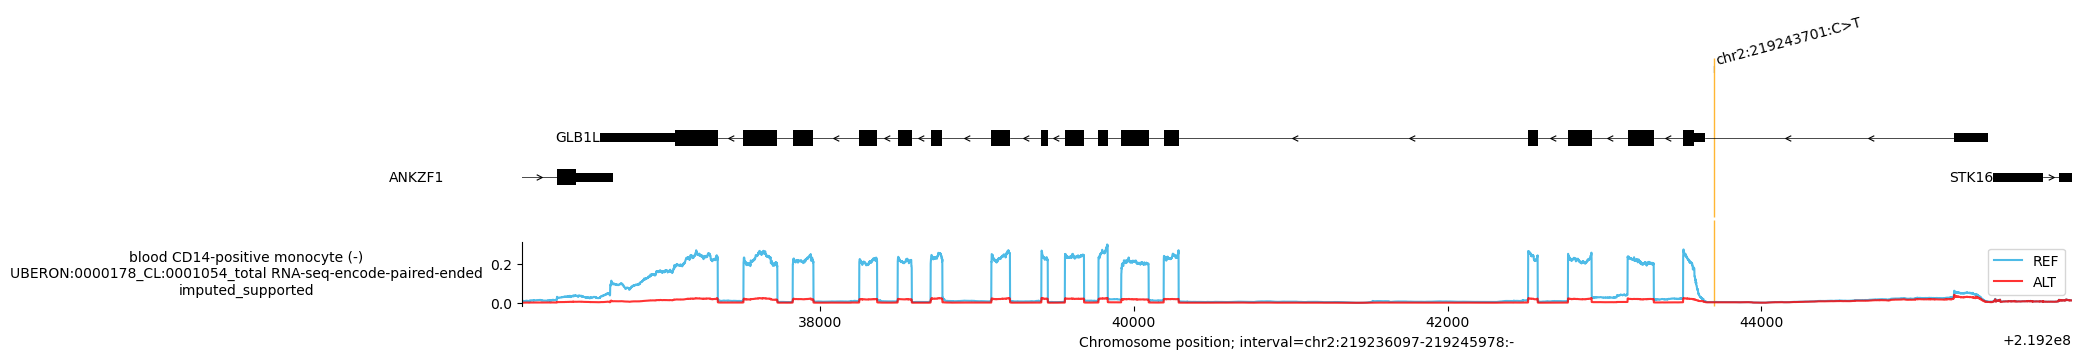

In [12]:
# Extract transcripts.
transcripts = transcript_extractor_mane.extract(interval)

# Plot.
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        # Subsetted RNA-seq.
        plot_components.OverlaidTracks(
            tdata={
                'REF': ref,
                'ALT': alt,
            },
            colors={'REF': '#22AAE1', 'ALT': 'red'},
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 1000),
    # Annotate the location of the variant as a vertical line.
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
plt.show()

AlphaGenome 2 predicts lower expression on the T alternate allele across the
negative-strand exons of *GLB1L*. When interpreting exon-level coverage,
prefer directly `observed` tracks (here paired-end `polyA plus RNA-seq`) over
`imputed_supported` predictions (`total RNA-seq` in this condition); see
[Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html).

```{tip}
For an example with a splicing variant, see
[Analyzing a splicing variant](https://www.alphagenomedocs.com/colabs/v2/splicing_variant.html).
```

## Predict variant (pseudobulk)

Variant prediction on pseudobulk scRNA-seq (`SC_GENE_EXPRESSION`) returns one
predicted expression value (in counts per million) per annotated gene in the
interval rather than a base-pair coverage track.

### Predict variant

We keep the same variant, interval, and condition (CD14-positive monocytes in
blood), and request scRNA-seq (`SC_GENE_EXPRESSION`) instead of bulk RNA-seq:

In [14]:
output_sc = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[dna_client.OutputType.SC_GENE_EXPRESSION],
    condition=target_condition,  # CD14-positive monocytes in blood.
)

`SC_GENE_EXPRESSION` returns a `GeneExpressionData` object with
`.track_metadata`, `.gene_metadata`, and `.values` of shape
`(num_genes, num_tracks)`:

In [15]:
output_sc.reference.sc_gene_expression.gene_metadata

,gene_id,Chromosome,Start,End,strand,gene_name,gene_type
0,ENSG00000054356.14,chr2,219289622,219309648,-,PTPRN,protein_coding
1,ENSG00000072182.14,chr2,219514169,219538772,+,ASIC4,protein_coding
2,ENSG00000072195.15,chr2,219434842,219493629,+,SPEG,protein_coding
3,ENSG00000114923.17,chr2,219627393,219641980,+,SLC4A3,protein_coding
4,ENSG00000115592.13,chr2,218822307,218832086,-,PRKAG3,protein_coding
...,...,...,...,...,...,...,...
68,ENSG00000286154.1,chr2,218799728,218802554,-,ENSG00000286154,lncRNA
69,ENSG00000286606.1,chr2,219065307,219070022,+,ENSG00000286606,lncRNA
70,ENSG00000287529.1,chr2,219198639,219200034,-,ENSG00000287529,lncRNA
71,ENSG00000288898.1,chr2,218909157,218939965,+,ENSG00000288898,lncRNA


Inspect the `.values` shape `(num_genes, num_tracks)`:

In [16]:
output_sc.reference.sc_gene_expression.values.shape

(73, 14)

Convert it to `AnnData` with `to_anndata` (see
[Key objects](https://www.alphagenomedocs.com/colabs/v2/key_objects.html)):

In [17]:
adata = output_sc.reference.sc_gene_expression.to_anndata()
adata

AnnData object with n_obs × n_vars = 73 × 14
    obs: 'gene_id', 'Chromosome', 'Start', 'End', 'strand', 'gene_name', 'gene_type'
    var: 'name', 'strand', 'biosample_curie', 'imputation_mode', 'biosample_type', 'biosample_name', 'Assay title', 'suspension_type', 'data_pipeline', 'cellxgene_dataset_id', 'paper_doi'
    uns: 'interval'
    layers: None (.X)

### Subset tracks

We select protein-coding genes on the negative strand and observed
negative-strand tracks, matching the strand of *GLB1L*:

In [18]:
ref = (
    output_sc.reference.sc_gene_expression.filter_to_protein_coding()  # Filter to protein-coding genes.
    .filter_to_observed()  # Filter to observed tracks.
    .filter_to_negative_strand()  # Filter to negative-strand tracks.
)
ref = ref[ref.gene_metadata['strand'] == '-']  # Restrict to negative-strand genes.

alt = (
    output_sc.alternate.sc_gene_expression.filter_to_protein_coding()
    .filter_to_observed()
    .filter_to_negative_strand()
)
alt = alt[alt.gene_metadata['strand'] == '-']

### Visualize

Use `plot_components.OverlaidGeneExpression` to plot paired REF and ALT
`SC_GENE_EXPRESSION` predictions across annotated genes in the interval:

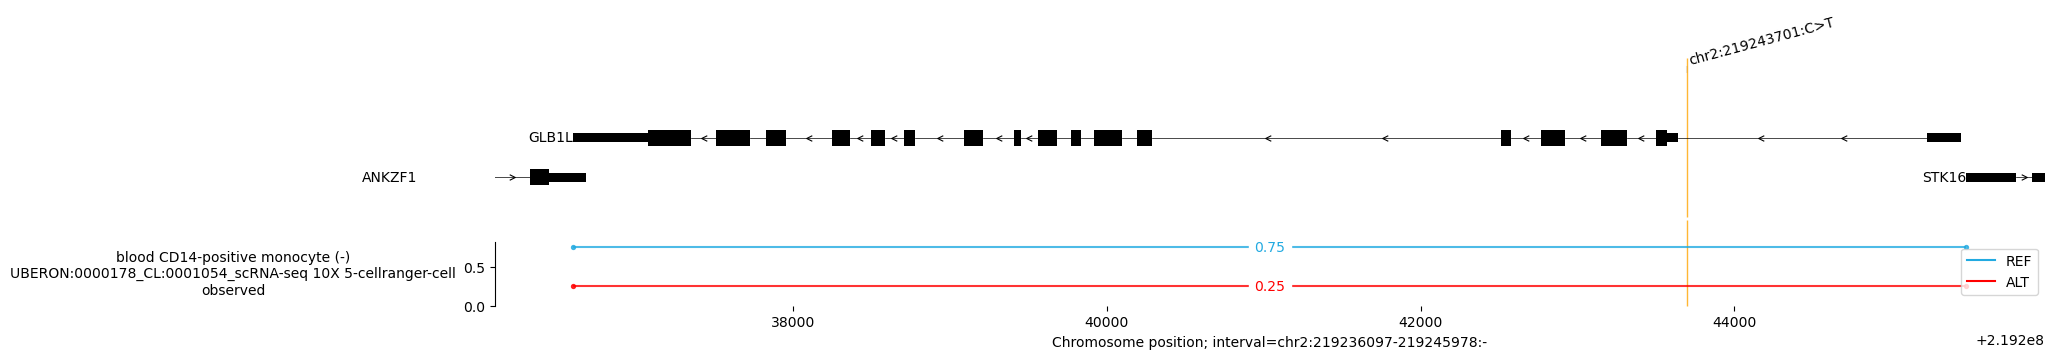

In [18]:
# Extract transcripts.
transcripts = transcript_extractor_mane.extract(interval)

# Plot.
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.OverlaidGeneExpression(
            gdata={
                'REF': ref,
                'ALT': alt,
            },
            colors={'REF': '#22AAE1', 'ALT': 'red'},
            log_scale=True,
            ylabel_template='{biosample_name} ({strand})\n{name}\n{imputation_mode}',
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 1000),
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
plt.show()

Unlike continuous `RNA_SEQ` tracks, which plot predicted read coverage across
individual genomic positions, `SC_GENE_EXPRESSION` predicts a single scalar
expression value per gene, drawn as a horizontal segment spanning each gene
body. AlphaGenome 2 predicts lower expression of *GLB1L* on the T alternate
allele at chr2:219243701.

See [Plotting predictions](https://www.alphagenomedocs.com/colabs/v2/plotting_predictions.html)
and the [visualization API reference](https://www.alphagenomedocs.com/api/visualization.html)
for additional plot customization.

Next in the core workflow, we will examine how to [score the variant](https://www.alphagenomedocs.com/colabs/v2/score_variant.html).